# 06 · El catálogo para los agentes

Después del [05 · resultado](05_resultado.ipynb), que enseña **qué datos tenemos**, este notebook enseña **cómo los
encuentra un agente**. El código está en [`catalogo_agentes.py`](../../../src/ingesta/mercados_series/catalogo_agentes.py)
(la búsqueda) y en [`herramientas/series.py`](../../../src/herramientas/series.py) (las tools); las reglas, en el
[README del tema](../../../src/ingesta/mercados_series/README.md) y en el de las
[herramientas](../../../src/herramientas/README.md).

**En una frase:** el catálogo es el **índice de la biblioteca**. Tiene una ficha por cada dato (qué mide, de dónde
sale, desde cuándo se puede ver y qué agente lo usa), pero **ningún número**. El agente primero busca en el índice y
luego pide el dato con la fecha de su decisión.

Este notebook solo lee la tabla del catálogo del repo (`catalogo_agentes.csv`), su YAML y, para la fecha de corte, el
manifiesto de la base curada. **No muestra ningún valor de serie ni de precio**: solo recuentos, fechas, ids, nombres,
temas, días de retraso y avisos. Las dos llamadas de ejemplo a las tools (sección 6) se enseñan con cada número
sustituido por «…».

**Palabras que salen mucho:**

- **Serie**: un dato que se publica cada cierto tiempo (el paro de cada mes, el tipo del bono cada día).
- **Precio**: la cotización diaria de un ticker (una acción, un ETF, un índice, el bitcoin).
- **Proyección**: lo que la Fed prevé para los próximos años (no es un dato observado).
- **Fecha de la decisión**: el día en que el agente decide. Lo pone el sistema, nunca el agente.
- **TimeGate**: la puerta que impide ver el futuro: solo pasa lo que ya se había publicado en esa fecha.
- **Primera publicación**: el primer día en que se pudo ver algo de un dato. Antes de ese día, para el agente, el
  dato no existe.
- **Aviso**: una nota de la ficha que explica una limitación del dato o qué usar en su lugar.

In [1]:
%matplotlib inline
%config InlineBackend.figure_formats = ['png']
import json
import re
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from matplotlib.colors import LogNorm
from matplotlib.patches import FancyBboxPatch, Patch

from herramientas import catalogo, invocar, json_schema
from ingesta.comun.rutas import corpus_dir, resultados_dir
from ingesta.mercados_series import catalogo_agentes as ca

plt.rcParams.update({'figure.dpi': 80, 'savefig.dpi': 80, 'font.size': 9, 'axes.titlesize': 11,
                     'axes.titleweight': 'bold', 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': 'white'})
pd.set_option('display.max_rows', 60)
pd.set_option('display.max_colwidth', 120)

# Paleta del 03, el 04 y el 05: verde = series (lo que «queda»), azul = precios, morado = proyecciones
COL_TIPO = {'serie': '#2b8a3e', 'precio': '#74c0fc', 'proyeccion': '#b197fc'}
NOMBRE_TIPO = {'serie': 'series', 'precio': 'precios', 'proyeccion': 'proyecciones'}
COL_OK, COL_MAL, COL_NA = '#2b8a3e', '#e03131', '#adb5bd'
COL_AVISO = '#ffa94d'
CMAP_INC = 'YlOrRd'
AGENTES = list(ca.AGENTES)                               # macro, risk, equity, portfolio, cio


def es(x, d=0):
    # número en formato español: 1.434 · 0,95
    s = f'{x:,.{d}f}'
    return s.replace(',', '§').replace('.', ',').replace('§', '.')


def tarjetas(items, filas, cols, titulo, alto=3.3):
    # cuadrícula de tarjetas (cifra, etiqueta, subtítulo, color), como en el 03, el 04 y el 05
    fig, axs = plt.subplots(filas, cols, figsize=(12.5, alto), gridspec_kw={'wspace': .06, 'hspace': .12})
    for ax in np.ravel(axs):
        ax.axis('off')
    for ax, (cifra, etq, sub, color) in zip(np.ravel(axs), items):
        ax.add_patch(plt.Rectangle((0, 0), 1, 1, fc='#f8f9fa', ec='#dee2e6', transform=ax.transAxes))
        ax.add_patch(plt.Rectangle((0, 0), .035, 1, fc=color, ec='none', transform=ax.transAxes))
        ax.text(.1, .66, cifra, fontsize=18, fontweight='bold', color='#212529', va='center', transform=ax.transAxes)
        ax.text(.1, .36, etq, fontsize=9.5, fontweight='bold', color='#495057', va='center', transform=ax.transAxes)
        ax.text(.1, .15, sub, fontsize=7.5, color='#495057', va='center', transform=ax.transAxes)
    fig.suptitle(titulo, fontweight='bold', x=.01, ha='left')
    fig.subplots_adjust(left=.01, right=.99, top=.86, bottom=.02)
    plt.show()


def mapa(ax, datos, filas, cols, cmap=CMAP_INC):
    # mapa de calor de recuentos en escala log, con el número en cada celda (como en el 03 y el 05)
    im = ax.imshow(np.where(datos > 0, datos, np.nan), cmap=cmap, norm=LogNorm(vmin=1, vmax=max(datos.max(), 2)),
                   aspect='auto')
    for i in range(datos.shape[0]):
        for j in range(datos.shape[1]):
            if datos[i, j] > 0:
                ax.text(j, i, int(datos[i, j]), ha='center', va='center', fontsize=8,
                        color='white' if np.log(datos[i, j]) > .65 * np.log(max(datos.max(), 2)) else 'black')
    ax.set_xticks(range(len(cols)), cols, fontsize=8)
    ax.set_yticks(range(len(filas)), filas, fontsize=8)
    for s in ax.spines.values():
        s.set_visible(False)
    return im


def apilar(ax, tabla, orden_tipos=('serie', 'precio', 'proyeccion'), etiquetas=True):
    # barras horizontales apiladas por tipo (tabla: filas = categorías, columnas = tipos)
    izq = np.zeros(len(tabla))
    for t in orden_tipos:
        if t in tabla:
            ax.barh(range(len(tabla)), tabla[t], left=izq, color=COL_TIPO[t], label=NOMBRE_TIPO[t])
            izq += tabla[t].to_numpy()
    if etiquetas:
        for i, v in enumerate(izq):
            ax.text(v, i, f' {es(v)}', va='center', fontsize=8, color='#495057')
    ax.set_yticks(range(len(tabla)), tabla.index)
    ax.invert_yaxis()
    ax.set_xlim(0, izq.max() * 1.15)


T = resultados_dir('mercados_series') / 'tablas'
CAT = ca.cargar_catalogo().copy()                       # la tabla del repo (results/.../catalogo_agentes.csv)
RES = pd.read_csv(T / 'catalogo_agentes_resumen.csv')
CFG = ca.cargar_config()
for c in ('desde', 'desde_inicial', 'desde_completo_en', 'primera_publicacion'):
    CAT[c] = pd.to_datetime(CAT[c])
CAT['lista_agentes'] = CAT['agentes'].fillna('').map(lambda s: [a for a in s.split('|') if a])
CAT['lista_avisos'] = CAT['avisos'].fillna('').map(lambda s: [a for a in s.split('; ') if a])
SER = CAT[CAT['tipo'] == 'serie'].copy()
PRE = CAT[CAT['tipo'] == 'precio'].copy()
PRO = CAT[CAT['tipo'] == 'proyeccion'].copy()

# Fecha de corte: la del manifiesto de la base curada (solo se lee esa clave); sin el corpus, la última publicación
_man = corpus_dir('mercados_series') / 'series' / 'curada_manifiesto.json'
CORTE = (pd.Timestamp(json.loads(_man.read_text(encoding='utf-8'))['corte_g2']) if _man.exists()
         else CAT['primera_publicacion'].max())
n = lambda m: int(np.sum(m))

# El catálogo cuadra con su resumen y no tiene ids repetidos
assert CAT['id'].is_unique
_rt = RES[RES['dimension'] == 'tipo'].set_index('categoria')['n']
assert all(_rt[t] == n(CAT['tipo'] == t) for t in ca.TIPOS)
assert set(CAT['tema']) <= set(ca.temas())
assert (CAT['primera_publicacion'] <= CORTE).all()
print(f"Catálogo: {es(len(CAT))} fichas ({len(SER)} series, {len(PRO)} proyecciones y {es(len(PRE))} precios), "
      f"{CAT['tema'].nunique()} temas, {CAT['zona'].nunique()} zonas; corte {CORTE.date()}. "
      "Cuadra con catalogo_agentes_resumen.csv.")

Catálogo: 2.011 fichas (514 series, 3 proyecciones y 1.494 precios), 19 temas, 46 zonas; corte 2026-11-13. Cuadra con catalogo_agentes_resumen.csv.


## 0. El catálogo en ocho cifras

**Qué vas a ver:** ocho tarjetas con lo esencial: cuántas fichas hay de cada tipo, en cuántos temas y zonas se reparten,
cuántas descripciones se repasaron a mano y la fecha de corte.

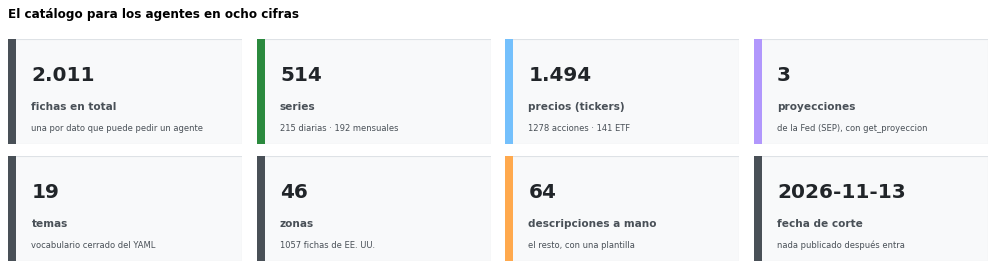

In [2]:
TARJ = [
    (es(len(CAT)), 'fichas en total', 'una por dato que puede pedir un agente', '#495057'),
    (es(len(SER)), 'series', f"{n(SER['frecuencia'] == 'diaria')} diarias · {n(SER['frecuencia'] == 'mensual')} mensuales",
     COL_TIPO['serie']),
    (es(len(PRE)), 'precios (tickers)', f"{n(PRE['clase'] == 'accion')} acciones · {n(PRE['clase'] == 'etf')} ETF",
     COL_TIPO['precio']),
    (es(len(PRO)), 'proyecciones', 'de la Fed (SEP), con get_proyeccion', COL_TIPO['proyeccion']),
    (es(CAT['tema'].nunique()), 'temas', 'vocabulario cerrado del YAML', '#495057'),
    (es(CAT['zona'].nunique()), 'zonas', f"{n(CAT['zona'] == 'US')} fichas de EE. UU.", '#495057'),
    (es(n(CAT['descripcion_manual'])), 'descripciones a mano', 'el resto, con una plantilla', COL_AVISO),
    (str(CORTE.date()), 'fecha de corte', 'nada publicado después entra', '#495057'),
]
tarjetas(TARJ, 2, 4, 'El catálogo para los agentes en ocho cifras')

**Qué significa:** el catálogo es pequeño comparado con los datos que describe (unas dos mil fichas frente a millones
de filas), y por eso un agente lo puede recorrer entero en cada búsqueda. La mayoría de las fichas son **precios de
acciones**; las **series** son menos, pero son las que cuentan la economía (tipos, inflación, empleo, crédito...).

## 1. Qué es el catálogo y para qué lo usa un agente

Imagina una biblioteca enorme. Los libros (los datos) están en el almacén, en `D:`, y no caben en la mesa. El
**catálogo** es el **fichero de la entrada**: una ficha por libro con el título, el tema y desde cuándo está en la
biblioteca, pero sin el contenido.

Un agente (un modelo de lenguaje con un papel: macro, riesgo, renta variable, cartera o director de inversiones) no
se sabe de memoria los ids de las series. Por eso trabaja en **dos pasos**:

1. **Busca** en el catálogo con palabras sencillas («inflación eurozona») usando `buscar_series`. Recibe una lista de
   fichas con su id.
2. **Pide** el dato con ese id usando `get_serie` (o `get_precios`, o `get_proyeccion`). Recibe un resumen y las
   últimas filas, con las citas de dónde sale.

En los dos pasos la **fecha de la decisión la pone el sistema**, no el agente. Así, si el agente está decidiendo en
2008, ni la búsqueda ni el dato le pueden enseñar nada que se publicara después (el **TimeGate**).

**Qué vas a ver:** un esquema de esos dos pasos.

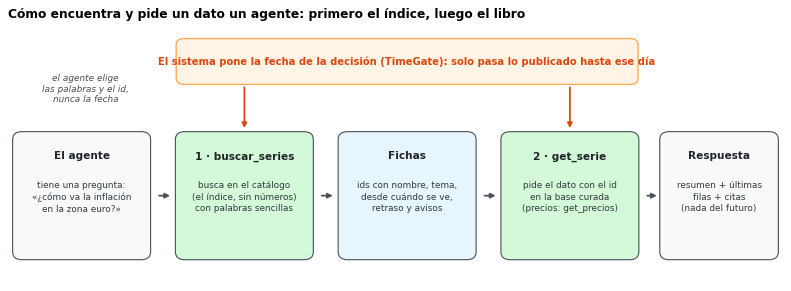

In [3]:
fig, ax = plt.subplots(figsize=(12.5, 4.2))
ax.set_xlim(0, 100)
ax.set_ylim(0, 40)
ax.axis('off')


def caja(x, y, w, h, titulo, texto, color):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.4,rounding_size=1.2', fc=color, ec='#495057',
                                lw=1))
    ax.text(x + w / 2, y + h - 2.6, titulo, ha='center', va='top', fontsize=9.5, fontweight='bold', color='#212529')
    ax.text(x + w / 2, y + h - 7.2, texto, ha='center', va='top', fontsize=8, color='#343a40', linespacing=1.35)


def flecha(x0, y0, x1, y1, texto='', color='#495057', estilo='-|>'):
    ax.annotate('', xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle=estilo, color=color, lw=1.6))
    if texto:
        ax.text((x0 + x1) / 2, (y0 + y1) / 2 + 1.2, texto, ha='center', va='bottom', fontsize=7.5, color=color)


Y, H, W = 4, 19, 17
caja(1, Y, W, H, 'El agente', 'tiene una pregunta:\n«¿cómo va la inflación\nen la zona euro?»', '#f8f9fa')
caja(22, Y, W, H, '1 · buscar_series', 'busca en el catálogo\n(el índice, sin números)\ncon palabras sencillas', '#d3f9d8')
caja(43, Y, W, H, 'Fichas', 'ids con nombre, tema,\ndesde cuándo se ve,\nretraso y avisos', '#e7f5ff')
caja(64, Y, W, H, '2 · get_serie', 'pide el dato con el id\nen la base curada\n(precios: get_precios)', '#d3f9d8')
caja(84.5, Y, 14.5, H, 'Respuesta', 'resumen + últimas\nfilas + citas\n(nada del futuro)', '#f8f9fa')
for x0, x1 in ((19.2, 21.2), (40.2, 42.2), (61.2, 63.2), (82.2, 84)):
    flecha(x0, Y + H / 2, x1, Y + H / 2)
# La fecha la pone el sistema: banda superior con flechas a los dos pasos
ax.add_patch(FancyBboxPatch((22, 31), 59, 6.5, boxstyle='round,pad=0.3,rounding_size=1', fc='#fff4e6', ec=COL_AVISO,
                            lw=1.2))
ax.text(51.5, 34.2, 'El sistema pone la fecha de la decisión (TimeGate): solo pasa lo publicado hasta ese día',
        ha='center', va='center', fontsize=9, fontweight='bold', color='#d9480f')
flecha(30.5, 30.6, 30.5, Y + H + 0.6, color='#d9480f')
flecha(72.5, 30.6, 72.5, Y + H + 0.6, color='#d9480f')
ax.text(10, 30, 'el agente elige\nlas palabras y el id,\nnunca la fecha', ha='center', va='center', fontsize=8,
        color='#495057', style='italic')
ax.set_title('Cómo encuentra y pide un dato un agente: primero el índice, luego el libro', loc='left')
plt.show()

**Qué significa:** el agente nunca tiene que adivinar un id como `ecb:HICP.M.U2.N.000000.4D0.ANR`. Le basta con
describir lo que busca. Y como la fecha va aparte, aunque el modelo «quisiera» mirar el futuro, no puede: la búsqueda
solo le enseña fichas de datos que ya existían ese día.

**Qué vas a ver:** una ficha de ejemplo, la del bono del Tesoro de EE. UU. a 10 años, con los campos que lee el agente.
Fíjate en que no hay ningún valor: solo qué es, desde cuándo se ve y con qué retraso se publica.

In [4]:
CAMPOS_FICHA = ['id', 'tipo', 'alias', 'nombre', 'descripcion', 'tema', 'subtema', 'zona', 'frecuencia', 'unidad',
                'fuente', 'desde', 'primera_publicacion', 'retraso_tipico_dias', 'agentes', 'avisos',
                'descripcion_manual']
fila = CAT[CAT['id'] == 'fred:DGS10'].iloc[0]
pd.DataFrame({'ficha de fred:DGS10': [str(fila[c].date()) if isinstance(fila[c], pd.Timestamp) else fila[c]
                                      for c in CAMPOS_FICHA]}, index=CAMPOS_FICHA)

,ficha de fred:DGS10
id,fred:DGS10
tipo,serie
alias,DGS10|ust:PAR.10Y
nombre,"Rendimiento del Tesoro de EE. UU. a 10 años (vencimiento constante, H.15)"
descripcion,"Rendimiento del bono del Tesoro de EE. UU. a 10 años, en % anual (diario, H.15). Es el tipo de referencia a largo pl..."
tema,curva
subtema,soberana
zona,US
frecuencia,diaria
unidad,% anual


**Qué significa:** cada ficha dice **qué** es el dato (nombre y descripción en castellano sencillo), **dónde** encaja
(tema, zona) y **cuándo** se pudo ver (`desde` es el primer periodo con dato; `primera_publicacion`, el primer día en
que algo de la serie era público). `retraso_tipico_dias` dice cuántos días suelen pasar entre el periodo y su
publicación, y `agentes`, a quién le sirve. Los `avisos` son las letras pequeñas.

## 2. Qué hay en el catálogo

**Qué vas a ver:** tres barras. A la izquierda, cuántas fichas hay de cada tipo. En el centro, las **series** por tema
y, a la derecha, los **precios** por tema (van separados porque los precios de acciones son tantos que taparían a todo
lo demás).

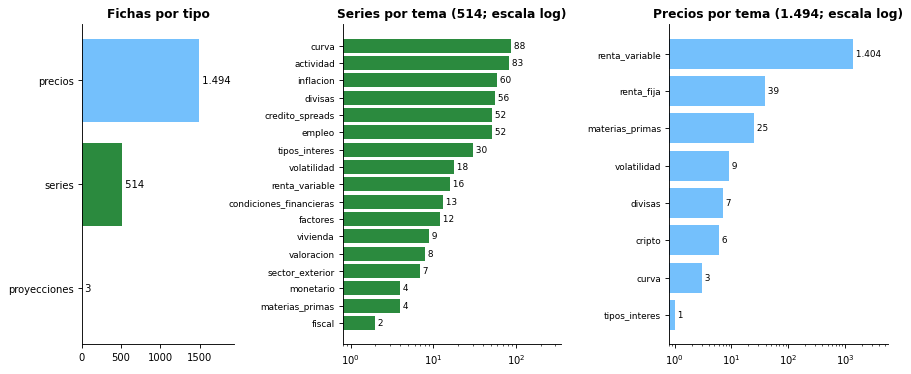

Proyecciones (3): fred:FEDTARMD (tipos_interes), fred:PCECTPIMD (inflacion), fred:UNRATEMD (empleo)


In [5]:
fig, axs = plt.subplots(1, 3, figsize=(13, 5.2), gridspec_kw={'width_ratios': [.7, 1, 1], 'wspace': .55})
por_tipo = CAT['tipo'].value_counts().reindex(['precio', 'serie', 'proyeccion'])
axs[0].barh(range(3), por_tipo, color=[COL_TIPO[t] for t in por_tipo.index])
for i, v in enumerate(por_tipo):
    axs[0].text(v, i, f' {es(v)}', va='center', fontsize=9)
axs[0].set_yticks(range(3), [NOMBRE_TIPO[t] for t in por_tipo.index])
axs[0].invert_yaxis()
axs[0].set_xlim(0, por_tipo.max() * 1.3)
axs[0].set_title('Fichas por tipo')
for ax, (df, t, tit) in zip(axs[1:], ((SER, 'serie', 'Series por tema'), (PRE, 'precio', 'Precios por tema'))):
    vc = df['tema'].value_counts()
    ax.barh(range(len(vc)), vc, color=COL_TIPO[t])
    for i, v in enumerate(vc):
        ax.text(v, i, f' {es(v)}', va='center', fontsize=8)
    ax.set_yticks(range(len(vc)), vc.index, fontsize=8)
    ax.invert_yaxis()
    ax.set_xscale('log')
    ax.set_xlim(.8, vc.max() * 4)
    ax.set_title(f'{tit} ({es(len(df))}; escala log)')
plt.show()
print('Proyecciones (3):', ', '.join(f"{r.id} ({r.tema})" for r in PRO.itertuples()))

**Qué significa:** las **series** están repartidas por muchos temas, con la curva de tipos, la actividad, el empleo,
la inflación y el crédito como los más grandes: es la parte «macro». Los **precios** están casi todos en renta
variable (acciones), y el resto son ETF de bonos, materias primas, índices de volatilidad, divisas y cripto. El eje es
logarítmico: cada marca multiplica por diez.

**Qué vas a ver:** las fichas por **zona** (las 10 con más fichas y el resto agrupado) y por **agente**. Una ficha
puede servir a varios agentes, así que la suma por agente es mayor que el total.

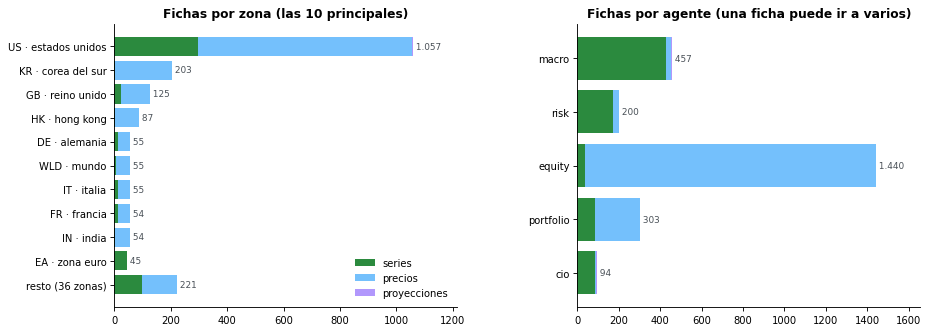

Fichas con un solo agente: 1553 · con dos o más: 458 · sin agente: 0. Las 36 zonas del resto suman 221 fichas.


In [6]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={'wspace': .35})
zt = pd.crosstab(CAT['zona'], CAT['tipo'])
zt = zt.loc[zt.sum(axis=1).sort_values(ascending=False).index]
top = zt.head(10)
resto = zt.iloc[10:]
zt10 = pd.concat([top, resto.sum().to_frame(f'resto ({len(resto)} zonas)').T])
NOM_ZONA = {c: (v[0] if v else c) for c, v in CFG.get('zona_nombres', {}).items()}
zt10.index = [f'{z} · {NOM_ZONA[z]}' if z in NOM_ZONA else z for z in zt10.index]
apilar(axs[0], zt10)
axs[0].set_title('Fichas por zona (las 10 principales)')
axs[0].legend(loc='lower right', frameon=False)
ag = CAT.explode('lista_agentes')
at = pd.crosstab(ag['lista_agentes'], ag['tipo']).reindex(AGENTES)
apilar(axs[1], at)
axs[1].set_title('Fichas por agente (una ficha puede ir a varios)')
plt.show()
print(f"Fichas con un solo agente: {n(CAT['lista_agentes'].map(len) == 1)} · con dos o más: "
      f"{n(CAT['lista_agentes'].map(len) >= 2)} · sin agente: {n(CAT['lista_agentes'].map(len) == 0)}. "
      f"Las {len(resto)} zonas del resto suman {es(resto.to_numpy().sum())} fichas.")

**Qué significa:** EE. UU. domina (más de la mitad de las fichas), porque ahí están casi todas las acciones del S&P 500 y
casi todas las series de FRED. Después vienen Corea, Reino Unido y Hong Kong, pero sobre todo por **acciones** de sus
índices; en **series**, la segunda zona es la del euro. Por agente, **equity** recibe casi todas las acciones y
**macro** casi todas las series; **cio** (el director) tiene pocas fichas porque solo ve la foto de conjunto.

**Qué vas a ver:** un mapa de calor con los **temas** en filas y los **agentes** en columnas. Cada casilla es el número
de fichas de ese tema que el catálogo recomienda a ese agente (todas las clases juntas). El color va en escala
logarítmica.

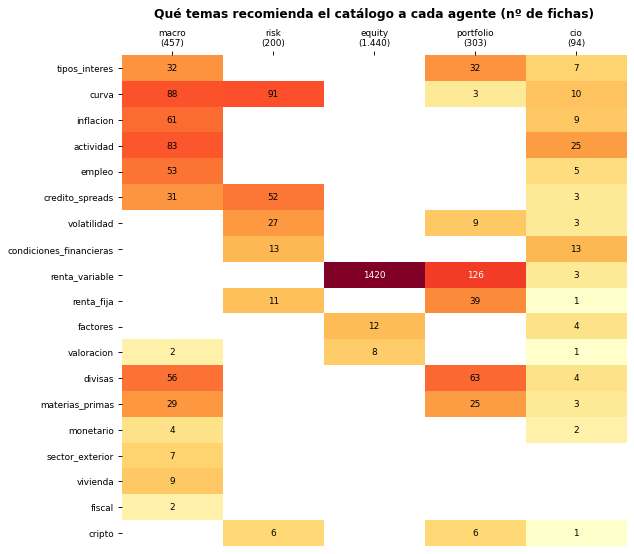

Temas sin ninguna ficha para cio: 3 de 19.


In [7]:
ht = pd.crosstab(ag['tema'], ag['lista_agentes']).reindex(index=ca.temas(), columns=AGENTES, fill_value=0)
fig, ax = plt.subplots(figsize=(8, 7))
mapa(ax, ht.to_numpy().astype(float), ht.index,
     [f'{a}\n({es(n(CAT["lista_agentes"].map(lambda l, a=a: a in l)))})' for a in AGENTES])
ax.xaxis.tick_top()
ax.set_title('Qué temas recomienda el catálogo a cada agente (nº de fichas)', pad=34)
plt.tight_layout()
plt.show()
sin_cio = [t for t in ca.temas() if ht.loc[t, 'cio'] == 0]
print(f"Temas sin ninguna ficha para cio: {len(sin_cio)} de {len(ht)}.")

**Qué significa:** cada agente tiene su «estantería»: **macro** la de tipos, inflación, actividad y empleo; **risk** la de
volatilidad, crédito, condiciones financieras y curva; **equity** la de renta variable, factores y valoración;
**portfolio** la de lo que se puede comprar (ETF, renta fija, divisas, materias primas). **cio** solo recibe lo que
resume el estado del mundo (estrés financiero, recesión, pendiente de la curva y las series clave). Es una
**recomendación**: con `buscar_series` sin filtro de agente, cualquiera puede encontrar cualquier ficha.

**Qué vas a ver:** cuántas descripciones se escribieron o repasaron **a mano** (las de las series clave) frente a las que
salen de una **plantilla**, y un ejemplo de cada.

In [8]:
dm = pd.crosstab(CAT['tipo'], CAT['descripcion_manual']).reindex(['serie', 'proyeccion', 'precio'])
dm.columns = ['plantilla', 'a mano']
dm['% a mano'] = (100 * dm['a mano'] / dm.sum(axis=1)).round(1)
display(dm)
man = CAT[CAT['descripcion_manual']]
display(Markdown('**Temas de las descripciones a mano:** ' + ' · '.join(
    f'{t} {k}' for t, k in man['tema'].value_counts().items())))
ej = pd.concat([CAT[CAT['id'] == 'fred:UNRATE'], CAT[(~CAT['descripcion_manual']) & (CAT['tipo'] == 'serie')
                                                    & (CAT['tema'] == 'empleo')].head(1)])
ej[['id', 'descripcion_manual', 'descripcion']]

,plantilla,a mano,% a mano
tipo,,,
serie,458,56,10.9
proyeccion,0,3,100.0
precio,1489,5,0.3


**Temas de las descripciones a mano:** inflacion 9 · curva 8 · actividad 7 · tipos_interes 7 · empleo 5 · divisas 4 · factores 4 · credito_spreads 3 · condiciones_financieras 3 · volatilidad 3 · materias_primas 3 · renta_variable 3 · monetario 2 · valoracion 1 · renta_fija 1 · cripto 1

,id,descripcion_manual,descripcion
370,fred:UNRATE,True,"Tasa de paro de EE. UU., en % de la población activa (mensual, desestacionalizada). Es el indicador clave del mercad..."
143,eurostat:une_rt_m.M.SA.TOTAL.PC_ACT.T.DE,False,"Tasa de paro 15-74, desestacionalizada (DE). Se mide en % población activa, con frecuencia mensual (Eurostat). Sirve..."


**Qué significa:** las series que más se van a usar (VIX, bono a 10 y a 2 años, pendientes de la curva, tipo de la Fed,
IPC, paro, NFCI, diferenciales de crédito, S&P 500, euro-dólar, HICP, tipos del BCE, factores de Ken French, CAPE...)
llevan una descripción pensada para el agente: qué mide, en qué unidad y para qué sirve. Las demás llevan una frase
de plantilla, correcta pero más pobre («Se mide en..., con frecuencia..., sirve para...»).

## 3. Historia disponible: desde cuándo se puede ver cada serie

**Qué vas a ver:** cuántas **series** se podían ver en cada año, desde 1990 hasta el corte, por tema. Una serie cuenta
en un año si su **primera publicación** es anterior al final de ese año (para el último año, al corte). Es lo que un
agente encontraría si decidiera ese año.

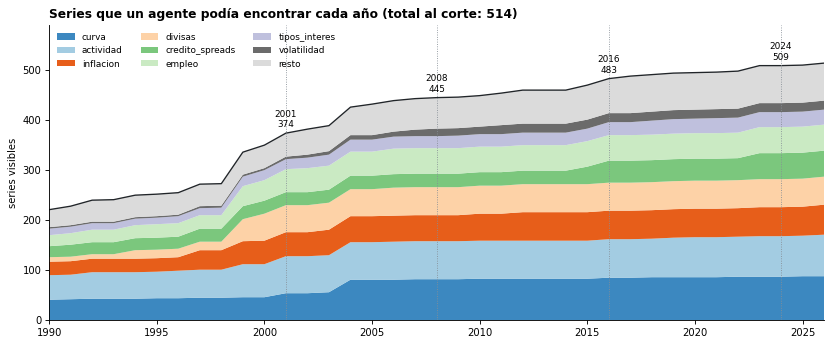

Visibles al final de 1990: 221 · 2000: 350 · 2007: 443 · 2015: 470 · corte: 514. Primera publicación desde 2016: 44 series.


In [9]:
ANIOS = list(range(1990, CORTE.year + 1))
fin = [min(pd.Timestamp(f'{a}-12-31'), CORTE) for a in ANIOS]
TEMAS_TOP = SER['tema'].value_counts().index[:8].tolist()
SER['tema_g'] = SER['tema'].where(SER['tema'].isin(TEMAS_TOP), 'resto')
grupos = TEMAS_TOP + ['resto']
vis = pd.DataFrame({g: [n((SER['tema_g'] == g) & (SER['primera_publicacion'] <= f)) for f in fin] for g in grupos},
                   index=ANIOS)
fig, ax = plt.subplots(figsize=(12.5, 4.8))
cols = plt.get_cmap('tab20c')(np.linspace(0, .95, len(grupos)))
ax.stackplot(ANIOS, vis.T.to_numpy(), labels=grupos, colors=cols, alpha=.95)
ax.plot(ANIOS, vis.sum(axis=1), color='#212529', lw=1.2)
for a in (2001, 2008, 2016, 2024):
    tot = int(vis.loc[a].sum())
    ax.axvline(a, color='#868e96', ls=':', lw=.8)
    ax.text(a, tot + 8, f'{a}\n{tot}', ha='center', va='bottom', fontsize=8)
ax.set_xlim(ANIOS[0], ANIOS[-1])
ax.set_ylim(0, len(SER) * 1.15)
ax.set_ylabel('series visibles')
ax.legend(loc='upper left', ncol=3, fontsize=8, frameon=False)
ax.set_title(f'Series que un agente podía encontrar cada año (total al corte: {len(SER)})', loc='left')
plt.show()
print(f"Visibles al final de 1990: {int(vis.loc[1990].sum())} · 2000: {int(vis.loc[2000].sum())} · "
      f"2007: {int(vis.loc[2007].sum())} · 2015: {int(vis.loc[2015].sum())} · corte: {int(vis.iloc[-1].sum())}. "
      f"Primera publicación desde 2016: {n(SER['primera_publicacion'] >= '2016-01-01')} series.")

**Qué significa:** en 1990 ya se veía algo menos de la mitad de las series; en 2000, unas dos de cada tres, y en 2007,
casi nueve de cada diez. Los saltos de los primeros años son fuentes que empiezan a publicar (o que la base curada fecha
con prudencia). Eso quiere decir que un backtest desde 2007 tiene casi todo el catálogo, y uno desde 2000, la mayor
parte. Lo que se añade después de 2016 son
series **nuevas o recortadas**: la siguiente tabla dice cuáles son y qué usar antes.

**Qué vas a ver:** las series que solo se ven **desde 2016 o después** (visibilidad tardía), agrupadas por familia, con
la fecha de su primera publicación y la **alternativa** que anuncia su aviso para fechas anteriores. A la izquierda, un
punto por serie; en naranja, las que no traen ninguna alternativa en el aviso.

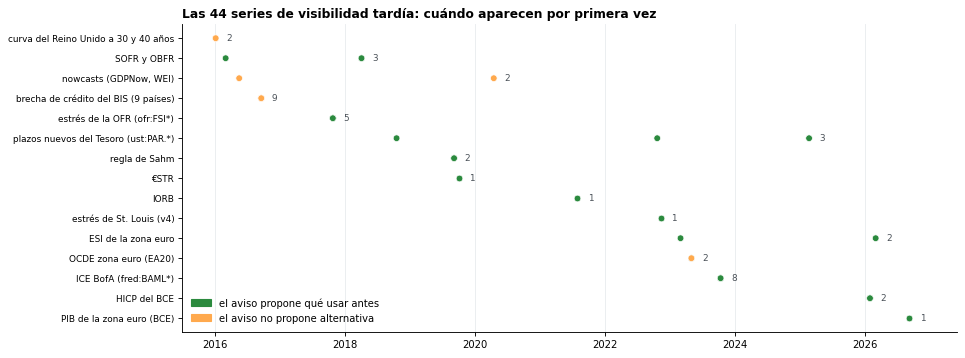

,series,visible desde,alternativa
familia,,,
curva del Reino Unido a 30 y 40 años,2,2016-01-06,—
SOFR y OBFR,3,2016-03-02 a 2018-04-04,"antes de su primera publicación, el tipo a un día en dólares es fred:EFFR (o fred:DFF)"
"nowcasts (GDPNow, WEI)",2,2016-05-17 a 2020-04-16,—
brecha de crédito del BIS (9 países),9,2016-09-18,—
estrés de la OFR (ofr:FSI*),5,2017-10-25,"publicada desde 2017-10-25: antes, fred:KCFSI o fred:CFSI"
plazos nuevos del Tesoro (ust:PAR.*),3,2018-10-18 a 2025-02-20,"plazo nuevo del Tesoro: antes, fred:DTB3 o fred:DGS1MO"
regla de Sahm,2,2019-09-06,"reconstruida desde 2019: para fechas anteriores, calcularla con fred:UNRATE"
€STR,1,2019-10-03,su historia anterior está en ecb:EONIA
IORB,1,2021-07-30,antes de 2021-07-29 la Fed remuneraba las reservas con IOER (no está en la base): fred:EFFR o fred:DFF


Con alternativa en el aviso: 30 de 44; sin ella: bis:WS_CREDIT_GAP.Q.CA.P.A.C, bis:WS_CREDIT_GAP.Q.CN.P.A.C, bis:WS_CREDIT_GAP.Q.DE.P.A.C, bis:WS_CREDIT_GAP.Q.FR.P.A.C, bis:WS_CREDIT_GAP.Q.GB.P.A.C, bis:WS_CREDIT_GAP.Q.IT.P.A.C, bis:WS_CREDIT_GAP.Q.JP.P.A.C, bis:WS_CREDIT_GAP.Q.US.P.A.C, bis:WS_CREDIT_GAP.Q.XM.P.A.C, boe:NOM.30Y, boe:NOM.40Y, fred:GDPNOW, fred:WEI, oecd:UNEMP.EA20.


In [10]:
FAMILIAS = [(r'^bis:WS_CREDIT_GAP', 'brecha de crédito del BIS (9 países)'), (r'^fred:BAML', 'ICE BofA (fred:BAML*)'),
            (r'^ofr:FSI', 'estrés de la OFR (ofr:FSI*)'), (r'^ust:PAR\.', 'plazos nuevos del Tesoro (ust:PAR.*)'),
            (r'^boe:NOM\.', 'curva del Reino Unido a 30 y 40 años'), (r'^fred:SAHM', 'regla de Sahm'),
            (r'^eurostat:ei_bssi', 'ESI de la zona euro'), (r'^(fred:(SOFR|OBFR)|deriv:SOFR)', 'SOFR y OBFR'),
            (r'^ecb:HICP', 'HICP del BCE'), (r'^ecb:ESTR', '€STR'), (r'^fred:IORB', 'IORB'),
            (r'^fred:STLFSI4', 'estrés de St. Louis (v4)'), (r'^oecd:', 'OCDE zona euro (EA20)'),
            (r'^fred:(GDPNOW|WEI)', 'nowcasts (GDPNow, WEI)'), (r'^ecb:MNA', 'PIB de la zona euro (BCE)')]
AVISOS_YAML = [str(r['aviso']) for r in CFG.get('avisos_reglas', [])]


def familia(i):
    return next((nom for pat, nom in FAMILIAS if re.search(pat, i)), i)


def alternativa(avisos):
    # qué anuncia el aviso para antes de la primera publicación (sin la etiqueta de visibilidad)
    limpio = [re.sub(r'\s*\[visible desde [\d-]+\]$', '', a) for a in avisos]
    for a in limpio:
        if a in AVISOS_YAML:
            return a
    prev = [a.replace('su historia anterior está en ', '') for a in limpio if a.startswith('su historia anterior')]
    if prev:
        return 'su historia anterior está en ' + ', '.join(prev)
    hp = [a for a in limpio if a.startswith('historia previa de ')]
    if hp:
        return f'es ella misma {hp[0]}'
    return '—'


TARD = SER[SER['primera_publicacion'] >= '2016-01-01'].copy()
TARD['familia'] = TARD['id'].map(familia)
TARD['alternativa'] = TARD['lista_avisos'].map(alternativa)
orden = TARD.groupby('familia')['primera_publicacion'].min().sort_values().index.tolist()
fig, ax = plt.subplots(figsize=(12.5, 5))
for k, fam in enumerate(orden):
    g = TARD[TARD['familia'] == fam]
    sin = g['alternativa'] == '—'
    ax.scatter(g['primera_publicacion'], [k] * len(g), s=36, color=np.where(sin, COL_AVISO, COL_TIPO['serie']),
               edgecolor='white', lw=.6, zorder=3)
    ax.text(g['primera_publicacion'].max() + pd.Timedelta(days=60), k, f'{len(g)}', va='center', fontsize=8,
            color='#495057')
ax.set_yticks(range(len(orden)), orden, fontsize=8)
ax.invert_yaxis()
ax.grid(axis='x', color='#e9ecef')
ax.set_xlim(pd.Timestamp('2015-07-01'), CORTE + pd.Timedelta(days=200))
ax.legend(handles=[Patch(color=COL_TIPO['serie'], label='el aviso propone qué usar antes'),
                   Patch(color=COL_AVISO, label='el aviso no propone alternativa')], loc='lower left', frameon=False)
ax.set_title(f'Las {len(TARD)} series de visibilidad tardía: cuándo aparecen por primera vez', loc='left')
plt.show()
tabla_t = (TARD.groupby('familia', sort=False)
           .agg(series=('id', 'size'), primera=('primera_publicacion', 'min'), ultima=('primera_publicacion', 'max'),
                alternativa=('alternativa', lambda s: ' / '.join(dict.fromkeys(s))))
           .loc[orden])
tabla_t['visible desde'] = [str(a.date()) if a == b else f'{a.date()} a {b.date()}'
                            for a, b in zip(tabla_t['primera'], tabla_t['ultima'])]
display(tabla_t[['series', 'visible desde', 'alternativa']])
print(f"Con alternativa en el aviso: {n(TARD['alternativa'] != '—')} de {len(TARD)}; sin ella: "
      f"{', '.join(TARD.loc[TARD['alternativa'] == '—', 'id'])}.")

**Qué significa:** hay tres motivos para que una serie se vea tarde:

- **es nueva** de verdad (el SOFR nació en 2018; el €STR, en 2019; el plazo de 6 semanas del Tesoro, en 2025);
- **la fuente solo da los últimos años** (FRED solo deja descargar 3 años de los índices ICE BofA, así que los
  diferenciales de crédito «oficiales» solo se ven desde 2023);
- **la base curada la fecha tarde** por prudencia (el HICP del BCE, la brecha de crédito del BIS).

Para casi todas, el aviso de la ficha dice qué usar antes (otra serie que ya existía o un ETF). Las que salen en naranja
no lo dicen: o no hay sustituto en la base o el sustituto evidente ya es otra ficha del mismo tema (por ejemplo, la
brecha de crédito no tiene otra serie parecida antes de 2016).

## 4. Retraso típico de publicación

Un dato del paro de marzo no se conoce el 31 de marzo, sino unos días después. El **retraso típico** de una ficha es
la mediana de esos días, medida en los 5 años antes del corte.

> **Ojo: es orientativo.** Es un número fijo por serie. En una fecha antigua el retraso pudo ser otro (una fuente que
> antes publicaba más tarde, o una fecha retrasada por prudencia). La verdad siempre es la `fecha_publicacion` de cada
> fila, que es lo que usa el TimeGate de `get_serie`.

**Qué vas a ver:** el retraso típico de las **series**, un punto por serie, por tema (izquierda) y por frecuencia
(derecha). La raya negra es la mediana del grupo. El eje es casi logarítmico: 0, 1, 10, 100 y 1.000 días quedan a la
misma distancia.

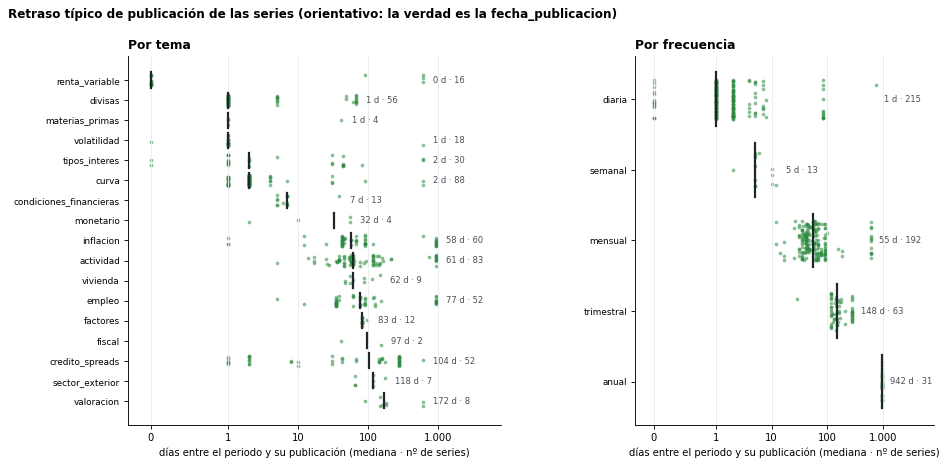

Precios: retraso típico 0 días en 1.458 tickers · 1 días en 36 tickers; proyecciones: sin retraso típico (se piden por edición).
Series anuales: 31, con 1 valor(es) distinto(s) de retraso típico (942 días).
Diarias con más de 30 días de retraso típico: ff:F3D.HML (83 d), ff:F3D.Mkt-RF (83 d), ff:F3D.RF (83 d), ff:F3D.SMB (83 d), ff:F5D.CMA (83 d), ff:F5D.RMW (83 d), ff:IND5D.Cnsmr (83 d), ff:IND5D.HiTec (83 d), ff:IND5D.Hlth (83 d), ff:IND5D.Manuf (83 d), ff:IND5D.Other (83 d), ff:MOMD.Mom (83 d), fred:USRECD (745 d)


In [11]:
def tiras(ax, df, col, orden, titulo):
    rng = np.random.default_rng(0)
    for k, g in enumerate(orden):
        v = df.loc[df[col] == g, 'retraso_tipico_dias'].dropna()
        ax.scatter(v, k + rng.uniform(-.28, .28, len(v)), s=11, alpha=.55, color=COL_TIPO['serie'], lw=0)
        ax.plot([v.median()] * 2, [k - .38, k + .38], color='#212529', lw=2)
        ax.text(v.max() * 1.4 + 1, k, f'{es(v.median())} d · {len(v)}', va='center', fontsize=7.5, color='#495057')
    ax.set_yticks(range(len(orden)), orden, fontsize=8)
    ax.invert_yaxis()
    ax.set_xscale('symlog', linthresh=1)
    ax.set_xlim(-.3, 8000)
    ax.set_xticks([0, 1, 10, 100, 1000], ['0', '1', '10', '100', '1.000'])
    ax.grid(axis='x', color='#e9ecef')
    ax.set_xlabel('días entre el periodo y su publicación (mediana · nº de series)')
    ax.set_title(titulo, loc='left')


fig, axs = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={'width_ratios': [1.25, 1], 'wspace': .4})
orden_t = SER.groupby('tema')['retraso_tipico_dias'].median().sort_values().index.tolist()
tiras(axs[0], SER, 'tema', orden_t, 'Por tema')
orden_f = [f for f in ('diaria', 'semanal', 'mensual', 'trimestral', 'anual') if f in set(SER['frecuencia'])]
tiras(axs[1], SER, 'frecuencia', orden_f, 'Por frecuencia')
fig.suptitle('Retraso típico de publicación de las series (orientativo: la verdad es la fecha_publicacion)',
             fontweight='bold', x=.01, ha='left')
plt.show()
rp = PRE['retraso_tipico_dias'].value_counts().sort_index()
print('Precios: retraso típico ' + ' · '.join(f'{int(k)} días en {es(v)} tickers' for k, v in rp.items())
      + '; proyecciones: sin retraso típico (se piden por edición).')
anual = SER[SER['frecuencia'] == 'anual']['retraso_tipico_dias']
print(f"Series anuales: {len(anual)}, con {anual.nunique()} valor(es) distinto(s) de retraso típico "
      f"({', '.join(es(x) for x in sorted(anual.unique()))} días).")
lentas_d = SER[(SER['frecuencia'] == 'diaria') & (SER['retraso_tipico_dias'] > 30)]
print('Diarias con más de 30 días de retraso típico:', ', '.join(f"{r.id} ({es(r.retraso_tipico_dias)} d)"
                                                                 for r in lentas_d.itertuples()))

**Qué significa:** los datos de **mercado** (tipos, curvas, volatilidad, divisas) se conocen al día siguiente o el mismo
día; los **mensuales** (paro, IPC) tardan de dos semanas a dos meses; los **trimestrales** (PIB, cuentas), varios meses;
y los **anuales** del Banco Mundial, más de dos años y medio (las 31 con el mismo número, porque su fecha sale de una
regla conservadora, no de una medida). Por tema, lo más lento es la valoración (beneficios y datos académicos), el
sector exterior, el crédito (la brecha de crédito del BIS es trimestral) y las cuentas públicas; lo más rápido, lo que
cotiza. Para un agente, esto sirve de
orientación («este dato llega con un mes de retraso») pero **no** para calcular fechas: eso lo hace la base curada fila
a fila.

Los puntos aislados muy a la derecha en «diaria» son casos especiales: los factores diarios de Ken French se publican
de golpe una vez al mes con unos tres meses de retraso, y la recesión diaria del NBER (`fred:USRECD`) se declara meses o
años después.

## 5. El TimeGate de la búsqueda

La búsqueda también respeta la fecha: una ficha no sale si su **primera publicación** es posterior a la fecha de la
decisión. Así, el catálogo no le «chiva» al agente que en el futuro habrá una serie nueva. También los avisos que solo
se sabían desde una fecha (por ejemplo, «la fuente dejó de publicarla») se esconden hasta esa fecha.

**Qué vas a ver:** a la izquierda, cuántas fichas del catálogo ve el agente en cuatro fechas (2001, 2008, 2016 y 2024) y
al corte. A la derecha, cuántos resultados devuelve la misma búsqueda en esas fechas (se piden hasta 50, que es el
tope de la tool).

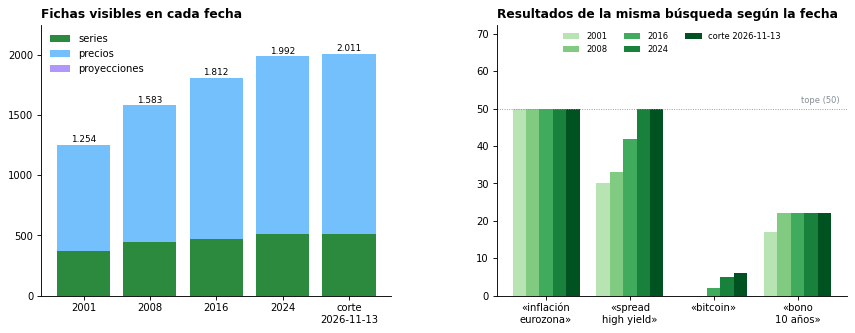

In [12]:
FECHAS = [date(2001, 6, 29), date(2008, 6, 30), date(2016, 6, 30), date(2024, 6, 28), CORTE.date()]
ETQ_F = [str(f.year) if f != CORTE.date() else f'corte\n{f}' for f in FECHAS]
BUSQUEDAS = ['inflación eurozona', 'spread high yield', 'bitcoin', 'bono 10 años']
vis_f = pd.DataFrame({t: [n((CAT['tipo'] == t) & (CAT['primera_publicacion'] <= pd.Timestamp(f))) for f in FECHAS]
                      for t in ('serie', 'precio', 'proyeccion')}, index=ETQ_F)
RB = {(q, f): ca.buscar_series(q, f, limite=ca.LIMITE_MAX) for q in BUSQUEDAS for f in FECHAS}
fig, axs = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={'wspace': .3})
izq = np.zeros(len(FECHAS))
for t in ('serie', 'precio', 'proyeccion'):
    axs[0].bar(range(len(FECHAS)), vis_f[t], bottom=izq, color=COL_TIPO[t], label=NOMBRE_TIPO[t])
    izq += vis_f[t].to_numpy()
for i, v in enumerate(izq):
    axs[0].text(i, v + 20, es(v), ha='center', fontsize=8)
axs[0].set_xticks(range(len(FECHAS)), ETQ_F)
axs[0].set_ylim(0, izq.max() * 1.12)
axs[0].legend(frameon=False, loc='upper left')
axs[0].set_title('Fichas visibles en cada fecha', loc='left')
w = .8 / len(FECHAS)
colf = plt.get_cmap('Greens')(np.linspace(.3, .95, len(FECHAS)))
for j, f in enumerate(FECHAS):
    vals = [len(RB[(q, f)]) for q in BUSQUEDAS]
    axs[1].bar(np.arange(len(BUSQUEDAS)) + (j - (len(FECHAS) - 1) / 2) * w, vals, w, color=colf[j],
               label=ETQ_F[j].replace('\n', ' '))
axs[1].axhline(ca.LIMITE_MAX, color='#868e96', ls=':', lw=.8)
axs[1].text(len(BUSQUEDAS) - .5, ca.LIMITE_MAX + 1, 'tope (50)', ha='right', va='bottom', fontsize=7.5, color='#868e96')
axs[1].set_xticks(range(len(BUSQUEDAS)), [f'«{q}»'.replace(' ', chr(10), 1) for q in BUSQUEDAS])
axs[1].set_ylim(0, ca.LIMITE_MAX * 1.45)
axs[1].legend(frameon=False, ncol=3, fontsize=7.5, loc='upper center')
axs[1].set_title('Resultados de la misma búsqueda según la fecha', loc='left')
plt.show()

**Qué significa:** el catálogo «crece» con el tiempo. En 2001 el agente ve muchas menos fichas que hoy, sobre todo porque
muchas acciones, ETF y criptoactivos todavía no cotizaban. La búsqueda «bitcoin» no devuelve **nada** en 2001 ni en 2008
(el bitcoin no existía o no cotizaba en Coinbase), y en 2024 ya incluye los ETF de bitcoin. «Inflación eurozona» toca el
tope de 50 en todas las fechas: la búsqueda es por palabras y «inflación» sola ya encaja con muchas fichas, así que lo
importante es **cuáles salen primero**.

**Qué vas a ver:** los 5 primeros ids de cada búsqueda en cada fecha (lo que el agente leería primero), sin valores.

In [13]:
tabla_b = pd.DataFrame({ETQ_F[j].replace('\n', ' '): [f"{len(RB[(q, f)])} · " + ', '.join(RB[(q, f)]['id'].head(5))
                                                        if len(RB[(q, f)]) else '0 · (nada)' for q in BUSQUEDAS]
                        for j, f in enumerate(FECHAS)}, index=[f'«{q}»' for q in BUSQUEDAS]).T
tabla_b.index.name = 'fecha'
display(tabla_b)
# El TimeGate también alcanza a los metadatos: un aviso con fecha solo aparece desde esa fecha
EJ_AV = 'eurostat:ei_bssi_m_r2.M.BS-ESI-I.SA.EA20'
crudo = CAT.loc[CAT['id'] == EJ_AV, 'avisos'].iloc[0]
filas_av = []
for f in (date(2024, 6, 28), CORTE.date()):
    visibles = (ca.avisos_en_fecha(crudo, pd.Timestamp(f)) or '').split('; ')
    filas_av.append({'fecha': str(f), 'nº de avisos visibles': len([a for a in visibles if a]),
                     '¿sale «retirada»?': any(a.startswith('retirada') for a in visibles),
                     '¿sale «historia previa de ...»?': any(a.startswith('historia previa de') for a in visibles)})
display(Markdown(f'**Avisos de `{EJ_AV}` (ESI de la zona euro, EA20) según la fecha:**'))
pd.DataFrame(filas_av)

,«inflación eurozona»,«spread high yield»,«bitcoin»,«bono 10 años»
fecha,,,,
2001,"50 · eurostat:HICP_EMP.EA, EZU, 6E=F, fred:PCE, fred:EXPINF10YR","30 · fred:TEDRATE, deriv:DBAA-DAAA, deriv:DBAA-DGS10, deriv:DGS10-DFF, deriv:DGS5-DFF",0 · (nada),"17 · fred:DGS10, deriv:DBAA-DGS10, fred:T10Y2Y, fred:T10Y3M, ^TNX"
2008,"50 · eurostat:HICP_EMP.EA, EZU, 6E=F, fred:PCE, fred:EXPINF10YR","33 · HYG, JNK, fred:TEDRATE, deriv:DBAA-DAAA, deriv:DBAA-DGS10",0 · (nada),"22 · fred:DGS10, deriv:DBAA-DGS10, ecb:YC.AAA.10Y, fred:DFII10, fred:T10Y2Y"
2016,"50 · wb:EMU.FP.CPI.TOTL.ZG, eurostat:HICP_EMP.EA, EZU, 6E=F, fred:PCE","42 · HYG, JNK, IHYU.L, fred:TEDRATE, deriv:DBAA-DAAA","2 · cb:BTC-USD, cb:ETH-USD","22 · fred:DGS10, deriv:DBAA-DGS10, ecb:YC.AAA.10Y, fred:DFII10, fred:T10Y2Y"
2024,"50 · wb:EMU.FP.CPI.TOTL.ZG, eurostat:HICP_EMP.EA, oecd:CP.EA20, EZU, 6E=F","50 · fred:BAMLH0A0HYM2, fred:BAMLH0A1HYBB, fred:BAMLH0A3HYC, HYG, JNK","5 · cb:BTC-USD, BITO, IBIT, ETHE, cb:ETH-USD","22 · fred:DGS10, deriv:DBAA-DGS10, ecb:YC.AAA.10Y, fred:DFII10, fred:T10Y2Y"
corte 2026-11-13,"50 · ecb:HICP.M.U2.N.000000.4D0.ANR, ecb:HICP.M.U2.N.XEF000.4D0.ANR, wb:EMU.FP.CPI.TOTL.ZG, eurostat:HICP_EMP.EA, oe...","50 · fred:BAMLH0A0HYM2, fred:BAMLH0A1HYBB, fred:BAMLH0A3HYC, HYG, JNK","6 · cb:BTC-USD, BITO, IBIT, ETHA, ETHE","22 · fred:DGS10, deriv:DBAA-DGS10, ecb:YC.AAA.10Y, fred:DFII10, fred:T10Y2Y"


**Avisos de `eurostat:ei_bssi_m_r2.M.BS-ESI-I.SA.EA20` (ESI de la zona euro, EA20) según la fecha:**

,fecha,nº de avisos visibles,¿sale «retirada»?,¿sale «historia previa de ...»?
0,2024-06-28,4,False,False
1,2026-11-13,6,True,True


**Qué significa:**

- **«inflación eurozona»**: antes de 2026 sale primero `eurostat:HICP_EMP.EA` (la historia previa del HICP) y, desde
  2016, la serie anual del Banco Mundial; el HICP **oficial del BCE** solo aparece al corte, porque la base curada lo
  fecha desde enero de 2026. Detrás salen fichas que solo comparten una palabra (el ETF `EZU`, el futuro del euro o la
  inflación de EE. UU.): la búsqueda no entiende de significado, solo de palabras.
- **«spread high yield»**: en 2001 no existe ningún índice de *high yield* en la base, así que salen diferenciales
  parecidos (`deriv:DBAA-DGS10`, el TED); desde 2008 aparecen los ETF `HYG` y `JNK`, y solo en 2024 los índices ICE
  BofA de FRED (`fred:BAMLH0A0HYM2`...).
- **«bitcoin»**: nada hasta que hay cotización; en 2016 sale `cb:BTC-USD` y, por la palabra «cripto», también el ether.
- **«bono 10 años»**: siempre sale primero `fred:DGS10`; desde 2008, también la curva AAA del BCE y el bono indexado
  `fred:DFII10`.

El ejemplo del ESI muestra que el TimeGate también esconde **avisos**: en 2024 el agente no sabe todavía que esa serie
será sustituida por otra ni que la fuente dejará de publicarla.

## 6. Las tools vistas por el LLM

Un modelo de lenguaje no lee Python. Lo que recibe de cada tool es un **esquema JSON**: el nombre, una frase que
explica qué hace y la lista de campos que puede rellenar, con su tipo y su explicación. La fecha **no** está entre esos
campos (la pone el sistema).

**Qué vas a ver:** primero, la frase de cada una de las 4 tools del Tema 1; después, sus campos uno a uno.

In [14]:
TOOLS_T1 = ['buscar_series', 'get_serie', 'get_precios', 'get_proyeccion']
ESQ = {t: json_schema(t) for t in TOOLS_T1}
assert all('fecha' not in e['parameters'].get('properties', {}) for e in ESQ.values())
display(pd.DataFrame([{'tool': t, 'lo que lee el LLM (description)': e['description']} for t, e in ESQ.items()]))


def tipo_json(p):
    # tipo legible de una propiedad del esquema JSON
    if 'anyOf' in p:
        partes = [tipo_json(q) for q in p['anyOf'] if q.get('type') != 'null']
        return ' o '.join(partes) + (' (opcional)' if any(q.get('type') == 'null' for q in p['anyOf']) else '')
    if 'enum' in p:
        return 'uno de: ' + ', '.join(map(str, p['enum']))
    if p.get('type') == 'array':
        return f"lista de {tipo_json(p.get('items', {}))}"
    t = {'string': 'texto', 'integer': 'entero', 'number': 'número', 'boolean': 'sí/no'}.get(p.get('type'), p.get('type'))
    if p.get('format') == 'date':
        t = 'fecha (AAAA-MM-DD)'
    return t or '?'


def limites(p):
    l = []
    for k, etq in (('minimum', '≥'), ('maximum', '≤'), ('minItems', 'mín. elementos'), ('maxItems', 'máx. elementos'),
                   ('minLength', 'longitud mín.')):
        if k in p:
            l.append(f'{etq} {p[k]}')
    return ', '.join(l)


filas_e = []
for t, e in ESQ.items():
    req = set(e['parameters'].get('required', []))
    for campo, p in e['parameters']['properties'].items():
        filas_e.append({'tool': t, 'campo': campo, 'tipo': tipo_json(p), 'obligatorio': 'sí' if campo in req else 'no',
                        'por defecto': '' if campo in req else str(p.get('default')), 'límites': limites(p),
                        'descripción': p.get('description', '')})
pd.set_option('display.max_colwidth', 260)
display(pd.DataFrame(filas_e).set_index(['tool', 'campo']))
pd.set_option('display.max_colwidth', 120)

,tool,lo que lee el LLM (description)
0,buscar_series,"Busca en el catálogo de datos del Tema 1 (series, precios, proyecciones) los ids que encajan con un texto o unos fil..."
1,get_serie,"Serie macro o de mercado tal como se conocía en la fecha de la decisión: resumen (último dato, cambios, percentil hi..."
2,get_precios,"Precios de acciones, ETF, índices o cripto conocidos en la fecha de la decisión: por ticker, resumen (rentabilidades..."
3,get_proyeccion,"Proyecciones de la Fed (SEP del FOMC) visibles en la fecha de la decisión: por periodo, la última edición publicada,..."


tipo  \
tool           campo                                                               
buscar_series  texto                                            texto (opcional)   
               tema                                             texto (opcional)   
               zona                                             texto (opcional)   
               agente     uno de: macro, equity, risk, portfolio, cio (opcional)   
               tipo                 uno de: serie, precio, proyeccion (opcional)   
               limite                                                     entero   
get_serie      id                                                          texto   
               desde                               fecha (AAAA-MM-DD) (opcional)   
               divisa                                      uno de: original, USD   
               max_filas                                                  entero   
get_precios    tickers                                            lista de texto   
               desde                               fecha (AAAA-MM-DD) (opcional)   
               ajuste                             uno de: ninguno, splits, total   
               divisa                                      uno de: USD, original   
               max_filas                                                  entero   
get_proyeccion id                                                          texto   
               desde                               fecha (AAAA-MM-DD) (opcional)   

                         obligatorio por defecto  \
tool           campo                               
buscar_series  texto              no        None   
               tema               no        None   
               zona               no        None   
               agente             no        None   
               tipo               no        None   
               limite             no          10   
get_serie      id                 sí               
               desde              no        None   
               divisa             no    original   
               max_filas          no          24   
get_precios    tickers            sí               
               desde              no        None   
               ajuste             no       total   
               divisa             no         USD   
               max_filas          no          20   
get_proyeccion id                 sí               
               desde              no        None   

                                                      límites  \
tool           campo                                            
buscar_series  texto                                            
               tema                                             
               zona                                             
               agente                                           
               tipo                                             
               limite                               ≥ 1, ≤ 50   
get_serie      id                             longitud mín. 1   
               desde                                            
               divisa                                           
               max_filas                           ≥ 0, ≤ 260   
get_precios    tickers    mín. elementos 1, máx. elementos 10   
               desde                                            
               ajuste                                           
               divisa                                           
               max_filas                           ≥ 0, ≤ 260   
get_proyeccion id                             longitud mín. 1   
               desde                                            

                                                                                                                                                                                                                                                              

**Qué significa:** las tools son pocas y con pocos campos, a propósito: cuanto más sencillo es el esquema, menos se
equivoca el modelo. `buscar_series` no tiene campos obligatorios (se puede buscar solo por filtros) y sus campos `tema`
y `zona` llevan en la descripción **el vocabulario real** del catálogo, para que el modelo no se invente un tema.
`get_serie` y `get_precios` devuelven por defecto un resumen y solo las últimas 24 o 20 filas, nunca la historia entera,
para no saturar al modelo. Ningún campo se llama `fecha`: el esquema lo comprueba.

**Qué vas a ver:** qué tools recibe cada agente (`catalogo(agente)`, a la izquierda) y, a la derecha, cuántas fichas le
recomienda el catálogo por tipo. Una casilla roja es una ficha recomendada que ese agente **no puede pedir** porque no
tiene la tool que la sirve.

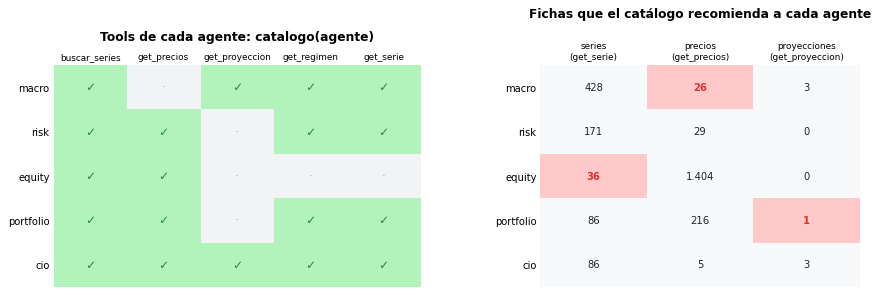

Fichas recomendadas sin la tool que las sirve: macro: 26 precios sin get_precios; equity: 36 series sin get_serie; portfolio: 1 proyecciones sin get_proyeccion.


In [15]:
TODAS = sorted({t.nombre for a in AGENTES for t in catalogo(a)})
mt = pd.DataFrame([[int(any(t.nombre == x for t in catalogo(a))) for x in TODAS] for a in AGENTES], index=AGENTES,
                  columns=TODAS)
TOOL_DE = {'serie': 'get_serie', 'precio': 'get_precios', 'proyeccion': 'get_proyeccion'}
fa = pd.crosstab(ag['lista_agentes'], ag['tipo']).reindex(index=AGENTES, columns=list(TOOL_DE), fill_value=0)
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={'width_ratios': [1.15, 1], 'wspace': .35})
axs[0].imshow(mt.to_numpy(), cmap=plt.matplotlib.colors.ListedColormap(['#f1f3f5', '#b2f2bb']), aspect='auto')
for i in range(len(AGENTES)):
    for j in range(len(TODAS)):
        axs[0].text(j, i, '✓' if mt.iloc[i, j] else '·', ha='center', va='center', fontsize=11,
                    color=COL_OK if mt.iloc[i, j] else '#adb5bd')
axs[0].set_xticks(range(len(TODAS)), TODAS, fontsize=8)
axs[0].set_yticks(range(len(AGENTES)), AGENTES)
axs[0].xaxis.tick_top()
axs[0].set_title('Tools de cada agente: catalogo(agente)', pad=22)
falta = np.array([[fa.iloc[i, j] > 0 and not mt.loc[a, TOOL_DE[t]] for j, t in enumerate(TOOL_DE)]
                  for i, a in enumerate(AGENTES)])
axs[1].imshow(np.where(falta, 1, 0), cmap=plt.matplotlib.colors.ListedColormap(['#f8f9fa', '#ffc9c9']), aspect='auto')
for i in range(len(AGENTES)):
    for j in range(len(TOOL_DE)):
        axs[1].text(j, i, es(fa.iloc[i, j]), ha='center', va='center', fontsize=9,
                    color=COL_MAL if falta[i, j] else '#212529', fontweight='bold' if falta[i, j] else 'normal')
axs[1].set_xticks(range(len(TOOL_DE)), [f'{NOMBRE_TIPO[t]}\n({TOOL_DE[t]})' for t in TOOL_DE], fontsize=8)
axs[1].set_yticks(range(len(AGENTES)), AGENTES)
axs[1].xaxis.tick_top()
axs[1].set_title('Fichas que el catálogo recomienda a cada agente', pad=22)
for ax in axs:
    for s in ax.spines.values():
        s.set_visible(False)
    ax.tick_params(length=0)
plt.show()
huecos = [(a, t, int(fa.loc[a, t])) for a in AGENTES for t in TOOL_DE if fa.loc[a, t] and not mt.loc[a, TOOL_DE[t]]]
print('Fichas recomendadas sin la tool que las sirve: ' + ('; '.join(
    f'{a}: {k} {NOMBRE_TIPO[t]} sin {TOOL_DE[t]}' for a, t, k in huecos) if huecos else 'ninguna') + '.')

**Qué significa:** todos los agentes tienen `buscar_series`; macro y cio, además, `get_proyeccion`; equity solo tiene
`buscar_series` y `get_precios`. `get_regimen` es la tool de la Fase 1 (el régimen de mercado), que no es del Tema 1 pero
vive en el mismo registro. Las casillas rojas son **incoherencias entre el catálogo y el reparto de tools**: el catálogo
le recomienda a un agente fichas que ese agente no puede pedir (por ejemplo, las series de factores y de valoración a
equity, que no tiene `get_serie`). Se recoge en las limitaciones (sección 7): hay que decidir si se le da la tool o si
se le quitan esas fichas.

**Qué vas a ver:** una llamada real con `invocar`, tal como la haría el sistema el 16 de marzo de 2020 (en plena caída por
el COVID): primero `get_serie` del bono a 10 años y luego `get_precios` de dos tickers. Se enseña **solo la estructura**
de la respuesta: los nombres de los campos, los avisos, las citas y cuántas filas llegan. **Cada número se ha
sustituido por «…»** (los datos tienen licencia y este repo es público).

In [16]:
def ocultar(x):
    # sustituye cada valor numérico por «…» (los sí/no y los textos se quedan)
    if isinstance(x, bool) or x is None:
        return x
    if isinstance(x, (int, float)):
        return '…'
    if isinstance(x, dict):
        return {k: ocultar(v) for k, v in x.items()}
    if isinstance(x, list):
        return [ocultar(v) for v in x]
    return x


def sin_numeros(x):
    # comprobación: no queda ningún int ni float (salvo sí/no)
    if isinstance(x, dict):
        return all(sin_numeros(v) for v in x.values())
    if isinstance(x, list):
        return all(sin_numeros(v) for v in x)
    return isinstance(x, bool) or not isinstance(x, (int, float))


def estructura(salida, recortar=('filas',)):
    # la salida como la recibe el LLM (JSON), sin números y con las listas de filas reducidas a una muestra
    d = ocultar(salida.model_dump(mode='json'))

    def recorta(o):
        if isinstance(o, dict):
            for k in list(o):
                if k in recortar and isinstance(o[k], list) and len(o[k]) > 1:
                    o[k] = [o[k][0], f'… y {len(o[k]) - 1} filas más con los mismos campos']
                else:
                    recorta(o[k])
        elif isinstance(o, list):
            for v in o:
                recorta(v)
        return o

    d = recorta(d)
    assert sin_numeros(d)
    return d


F_EJ = date(2020, 3, 16)
s_ej = invocar('get_serie', {'id': 'fred:DGS10', 'max_filas': 5}, fecha=F_EJ)
print(f'invocar("get_serie", {{"id": "fred:DGS10", "max_filas": 5}}, fecha={F_EJ})  →  {len(s_ej.filas)} filas, '
      f'{len(s_ej.avisos)} aviso(s), {len(s_ej.citas)} cita(s)\n')
print(json.dumps(estructura(s_ej), ensure_ascii=False, indent=1))

invocar("get_serie", {"id": "fred:DGS10", "max_filas": 5}, fecha=2020-03-16)  →  5 filas, 1 aviso(s), 1 cita(s)

{
 "tool": "get_serie",
 "fecha_consulta": "2020-03-16",
 "citas": [
  {
   "fuente": "mercados_series/base_curada.parquet",
   "id": "1081a21c6fc3648120672b328cfc4a78384a3822fbd0e4a6091adf7fe463c9a4",
   "fecha_publicacion": "2020-03-16",
   "url": null,
   "fragmento": null
  }
 ],
 "avisos": [
  "fecha de publicación del tramo conservador (antes del corte de lista_curada.yaml la fecha no es fiable: se retrasa con la regla conservadora) en 10852 periodos: tramo conservador de H.15 diario antes de 2005-06-28: 7D más (preprocesado.yaml, h15_diario)"
 ],
 "id": "fred:DGS10",
 "id_servido": "fred:DGS10",
 "encontrado": true,
 "nombre": "Rendimiento del Tesoro de EE. UU. a 10 años (vencimiento constante, H.15)",
 "unidad": "% anual",
 "frecuencia": "diaria",
 "divisa": null,
 "resumen": {
  "ultimo_valor": "…",
  "fecha_referencia": "2020-03-13",
  "fecha_publicacion": "2020-03

In [17]:
p_ej = invocar('get_precios', {'tickers': ['SPY', 'cb:BTC-USD'], 'max_filas': 3}, fecha=F_EJ)
print(f'invocar("get_precios", {{"tickers": ["SPY", "cb:BTC-USD"], "max_filas": 3}}, fecha={F_EJ})  →  '
      + ', '.join(f'{t.ticker}: {len(t.filas)} filas' for t in p_ej.tickers)
      + f'; {len(p_ej.avisos)} aviso(s), {len(p_ej.citas)} cita(s)\n')
print(json.dumps(estructura(p_ej), ensure_ascii=False, indent=1))

invocar("get_precios", {"tickers": ["SPY", "cb:BTC-USD"], "max_filas": 3}, fecha=2020-03-16)  →  SPY: 3 filas, cb:BTC-USD: 3 filas; 0 aviso(s), 2 cita(s)

{
 "tool": "get_precios",
 "fecha_consulta": "2020-03-16",
 "citas": [
  {
   "fuente": "mercados_series/precios_curados/yahoo/SPY.parquet",
   "id": "93a489b219e2aa9d777c25e22f3e25598b371638310214bf8f7971a3cc890ca1",
   "fecha_publicacion": "2020-03-16",
   "url": null,
   "fragmento": null
  },
  {
   "fuente": "mercados_series/precios_curados/coinbase/cb~3ABTC-USD.parquet",
   "id": "dbb47ac20468a5ae3f07fc1c32b8e7bfd41013baacc4cd3cec3634e82d52504c",
   "fecha_publicacion": "2020-03-16",
   "url": null,
   "fragmento": null
  }
 ],
 "avisos": [],
 "ajuste": "total",
 "divisa": "USD",
 "tickers": [
  {
   "ticker": "SPY",
   "ticker_servido": null,
   "encontrado": true,
   "mercado": "ARCX",
   "divisa": "USD",
   "resumen": {
    "ultima_sesion": "2020-03-16",
    "ultimo_cierre": "…",
    "rentabilidad_1m": "…",
    "rentabilidad

**Qué significa:** la respuesta siempre tiene la misma forma: **de qué tool viene y a qué fecha** (`tool`,
`fecha_consulta`), **de dónde sale** (`citas`, con la huella del fichero, que luego cita el memo final), **qué hay que
saber** (`avisos`) y el dato: un **resumen** (último valor, cambios, percentil...) y unas pocas **filas**. Las fechas sí
se ven: todas son anteriores o iguales al 16 de marzo de 2020. En `get_precios` cada ticker lleva su propio bloque.

**Qué vas a ver:** qué pasa si el agente pide algo que **todavía no existía**: el índice de estrés de la OFR en plena
quiebra de Lehman (2008), cuando ese índice no se publicaba aún.

In [18]:
nf = invocar('get_serie', {'id': 'ofr:FSI'}, fecha=date(2008, 9, 15))
print(json.dumps(estructura(nf), ensure_ascii=False, indent=1))

{
 "tool": "get_serie",
 "fecha_consulta": "2008-09-15",
 "citas": [
  {
   "fuente": "mercados_series/base_curada.parquet",
   "id": "1081a21c6fc3648120672b328cfc4a78384a3822fbd0e4a6091adf7fe463c9a4",
   "fecha_publicacion": null,
   "url": null,
   "fragmento": null
  }
 ],
 "avisos": [
  "serie 'ofr:FSI' sin datos publicados hasta 2008-09-15 (desconocida o aún no publicada). Usa buscar_series para encontrar el id correcto."
 ],
 "id": "ofr:FSI",
 "id_servido": null,
 "encontrado": false,
 "nombre": null,
 "unidad": null,
 "frecuencia": null,
 "divisa": null,
 "resumen": null,
 "filas": [],
 "filas_omitidas": "…"
}


**Qué significa:** la tool **no falla** ni avisa de que la serie existirá: contesta `encontrado: false` con un aviso
neutro, el mismo que para un id inventado, y le sugiere usar `buscar_series`. Si el agente busca «estrés financiero» en
2008, el catálogo le dará las alternativas que ya existían (`fred:KCFSI`, `fred:CFSI`, `fred:NFCI`).

## 7. Limitaciones del catálogo

Contadas en sencillo. Cada una lleva su comprobación.

### 7.1 Muchas acciones no tienen nombre

**Qué vas a ver:** las acciones del catálogo según tengan nombre de empresa o solo el ticker («Acción AAPL»), por zona;
y qué devuelve la búsqueda por el nombre y por el ticker.

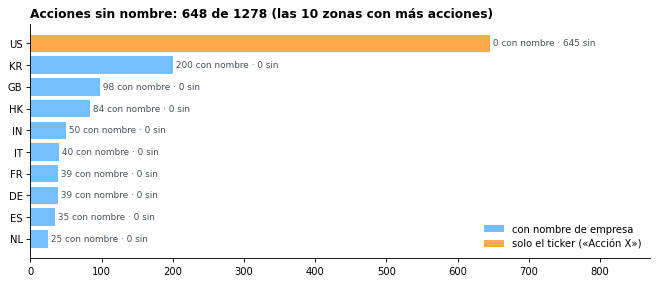

Búsquedas el 2024-06-28: «Apple» → 0 resultado(s) · «AAPL» → 1 resultado(s) · «Microsoft» → 0 resultado(s) · «MSFT» → 1 resultado(s)
Sin nombre por zona: {'US': 645, 'JP': 2, 'TW': 1}


In [19]:
ACC = CAT[(CAT['tipo'] == 'precio') & (CAT['clase'] == 'accion')].copy()
ACC['sin_nombre'] = ACC['nombre'].str.match(r'^Acción \S+$')
zn = pd.crosstab(ACC['zona'], ACC['sin_nombre']).rename(columns={False: 'con nombre', True: 'solo el ticker'})
zn = zn.loc[zn.sum(axis=1).sort_values(ascending=False).index].head(10)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(range(len(zn)), zn['con nombre'], color=COL_TIPO['precio'], label='con nombre de empresa')
ax.barh(range(len(zn)), zn['solo el ticker'], left=zn['con nombre'], color=COL_AVISO, label='solo el ticker («Acción X»)')
for i, (a, b) in enumerate(zip(zn['con nombre'], zn['solo el ticker'])):
    ax.text(a + b, i, f' {a} con nombre · {b} sin', va='center', fontsize=8, color='#495057')
ax.set_yticks(range(len(zn)), zn.index)
ax.invert_yaxis()
ax.set_xlim(0, zn.sum(axis=1).max() * 1.35)
ax.legend(frameon=False, loc='lower right')
ax.set_title(f"Acciones sin nombre: {n(ACC['sin_nombre'])} de {len(ACC)} (las 10 zonas con más acciones)", loc='left')
plt.show()
F24 = date(2024, 6, 28)
demo = [(q, len(ca.buscar_series(q, F24, limite=ca.LIMITE_MAX))) for q in ('Apple', 'AAPL', 'Microsoft', 'MSFT')]
print(f'Búsquedas el {F24}: ' + ' · '.join(f'«{q}» → {k} resultado(s)' for q, k in demo))
print('Sin nombre por zona:', ACC[ACC['sin_nombre']]['zona'].value_counts().to_dict())

**Qué significa:** la lista del S&P 500 que tenemos solo trae tickers, no nombres de empresa. Por eso casi todas las
acciones de EE. UU. (todas las de la figura) se llaman «Acción AAPL», «Acción MSFT»... Si el agente busca «Apple», **no encuentra nada**; si
busca «AAPL», sí. Las acciones de otros índices (FTSE, DAX, Hang Seng, KOSPI...) sí tienen nombre, porque la foto de su
índice lo trae. Arreglo posible: añadir un fichero de nombres de las empresas del S&P 500 con licencia compatible.

### 7.2 El retraso típico es un número fijo

`retraso_tipico_dias` se midió una vez, con los 5 años antes del corte, y **no cambia con la fecha de la decisión**. Si en
2002 una fuente publicaba más tarde que hoy, la ficha no lo dice. No es un problema de fuga de información (el TimeGate
de los datos usa la `fecha_publicacion` de cada fila, no este número), pero el agente podría esperar un dato antes de
tiempo.

In [20]:
cambia = SER['avisos'].fillna('').str.contains('tramo conservador|reconstruida hacia atrás|fechas conservadoras')
print(f"Series cuyo aviso dice que en el pasado su fecha de publicación fue otra (tramo conservador, fechas "
      f"conservadoras o reconstrucción): {n(cambia)} de {len(SER)}. En ellas el retraso típico de hoy no describe "
      "bien el de las fechas antiguas.")

Series cuyo aviso dice que en el pasado su fecha de publicación fue otra (tramo conservador, fechas conservadoras o reconstrucción): 106 de 514. En ellas el retraso típico de hoy no describe bien el de las fechas antiguas.


### 7.3 Dos huecos que el catálogo no puede tapar

- **Inflación subyacente de la zona euro antes de enero de 2026.** El HICP subyacente del BCE solo se ve desde el
  2026-01-28 y no hay ninguna serie anterior que lo sustituya (de la inflación general sí hay historia previa).
- **Diferenciales de crédito ICE BofA (OAS) antes de octubre de 2023.** FRED solo deja descargar los 3 últimos años,
  así que antes hay que usar aproximaciones: `deriv:DBAA-DGS10`, `deriv:DBAA-DAAA` o los ETF `HYG`, `JNK` y `LQD`.

**Qué vas a ver:** la búsqueda antes y después de cada hueco (los 4 primeros ids).

In [21]:
HUECOS = [('inflación subyacente zona euro', date(2025, 12, 31)), ('inflación subyacente zona euro', CORTE.date()),
          ('oas high yield', date(2023, 6, 30)), ('oas high yield', date(2024, 6, 28))]
pd.DataFrame([{'búsqueda': f'«{q}»', 'fecha': str(f), 'resultados': len(r := ca.buscar_series(q, f, limite=ca.LIMITE_MAX)),
               'primeros ids': ', '.join(r['id'].head(4))} for q, f in HUECOS])

,búsqueda,fecha,resultados,primeros ids
0,«inflación subyacente zona euro»,2025-12-31,50,"fred:CPILFESL, oecd:CP.EA20, fred:CORESTICKM159SFRBATL, fred:CUSR0000SACL1E"
1,«inflación subyacente zona euro»,2026-11-13,50,"ecb:HICP.M.U2.N.XEF000.4D0.ANR, ecb:HICP.M.U2.N.000000.4D0.ANR, fred:CPILFESL, oecd:CP.EA20"
2,«oas high yield»,2023-06-30,4,"HYG, IHYU.L, JNK, deriv:DBAA-DGS10"
3,«oas high yield»,2024-06-28,11,"fred:BAMLH0A0HYM2, fred:BAMLH0A1HYBB, fred:BAMLH0A3HYC, HYG"


**Qué significa:** antes de 2026, «inflación subyacente zona euro» devuelve primero la **subyacente de EE. UU.**
(`fred:CPILFESL`), porque no hay otra cosa; un agente poco cuidadoso podría tomarla por la europea, así que tiene que
leer la `zona` de la ficha. Con el OAS pasa lo mismo, pero aquí la búsqueda sí ofrece sustitutos razonables (los ETF de
*high yield* y el diferencial Baa).

### 7.4 Algunos temas son discutibles

El tema de cada ficha sale de reglas del YAML (por fuente, grupo o patrón de id). Funcionan bien en general, pero
algunos casos se podrían colocar en otro sitio. **Qué vas a ver:** unos ejemplos sacados del propio catálogo.

In [22]:
DISCUTIBLES = {
    'fred:CP': 'beneficios de las empresas en «valoración»: también es actividad',
    'fred:TEDRATE': 'el diferencial TED en «crédito»: también es un tipo interbancario',
    '^IRX': 'la letra a 13 semanas en «tipos de interés», pero ^FVX y ^TNX en «curva»',
    '^TNX': 'el índice del bono a 10 años es un precio en el tema «curva»',
    'GC=F': 'el futuro del oro tiene subtema «precios»; GLD e IAU, subtema «oro»',
    'GLD': 'el ETF del oro, subtema «oro»',
    'ZW=F': 'el trigo en el subtema «amplio», como las cestas de materias primas',
    'VIXY': 'un ETF de futuros del VIX en «volatilidad», no en los ETF de cartera',
    'yf:^GSPC': 'el S&P 500 como serie de renta variable y, además, como precio (^GSPC)',
}
disc = CAT[CAT['id'].isin(DISCUTIBLES)].set_index('id').loc[list(DISCUTIBLES)]
disc = disc[['tipo', 'nombre', 'tema', 'subtema', 'agentes']].assign(**{'por qué es discutible': list(DISCUTIBLES.values())})
display(disc)
dup = sorted(set(SER['id'].str.replace('^yf:', '', regex=True)) & set(PRE['id']))
print(f'Ids que están a la vez como serie (yf:...) y como precio: {len(dup)} ({", ".join(dup[:8])}'
      + (', ...' if len(dup) > 8 else '') + ').')

,tipo,nombre,tema,subtema,agentes,por qué es discutible
id,,,,,,
fred:CP,serie,"Beneficios empresariales después de impuestos, sin IVA ni CCAdj (tasa anual)",valoracion,beneficios,macro|equity,beneficios de las empresas en «valoración»: también es actividad
fred:TEDRATE,serie,TED spread (LIBOR 3M en USD menos letra a 3 meses),credito_spreads,financiacion,risk,el diferencial TED en «crédito»: también es un tipo interbancario
^IRX,precio,Índice Cboe de la letra del Tesoro a 13 semanas,tipos_interes,letras,macro|portfolio,"la letra a 13 semanas en «tipos de interés», pero ^FVX y ^TNX en «curva»"
^TNX,precio,Índice Cboe del rendimiento del Tesoro a 10 años,curva,soberana,risk|portfolio,el índice del bono a 10 años es un precio en el tema «curva»
GC=F,precio,Oro (continuo),materias_primas,precios,macro|portfolio,"el futuro del oro tiene subtema «precios»; GLD e IAU, subtema «oro»"
GLD,precio,SPDR Gold Shares,materias_primas,oro,macro|portfolio|cio,"el ETF del oro, subtema «oro»"
ZW=F,precio,Trigo (continuo),materias_primas,amplio,macro|portfolio,"el trigo en el subtema «amplio», como las cestas de materias primas"
VIXY,precio,ProShares VIX Short-Term Futures ETF,volatilidad,renta_variable,risk|portfolio,"un ETF de futuros del VIX en «volatilidad», no en los ETF de cartera"
yf:^GSPC,serie,Índice S&P 500 (precio),renta_variable,indices,equity|cio,"el S&P 500 como serie de renta variable y, además, como precio (^GSPC)"


Ids que están a la vez como serie (yf:...) y como precio: 25 (DX-Y.NYB, GC=F, ^DJI, ^FVX, ^GSPC, ^IRX, ^IXIC, ^MOVE, ...).


**Qué significa:** ninguno de estos casos rompe nada (la búsqueda mira también el nombre, las palabras clave y la
descripción, no solo el tema), pero un agente que filtre por tema podría perderse algo. Por ejemplo, si filtra
`tema='curva'` no verá la letra a 13 semanas. Es un ajuste fino del YAML para cuando se construyan los agentes.

Otras limitaciones, más pequeñas:

- La búsqueda es **por palabras**, no por significado: «inflación eurozona» también devuelve el ETF `EZU` o el futuro
  del euro porque comparten una palabra. Los sinónimos se mantienen a mano en el YAML.
- El catálogo le recomienda a algunos agentes fichas que **no pueden pedir** con sus tools (sección 6).

## 8. Resumen

In [23]:
n_alt = n(TARD['alternativa'] != '—')
display(Markdown(
    f"- **Qué es:** un índice de {es(len(CAT))} fichas ({len(SER)} series, {len(PRO)} proyecciones y {es(len(PRE))} "
    f"precios) con qué mide cada dato, su tema, su zona, desde cuándo se ve y a qué agente sirve; **sin ningún valor**. "
    f"{n(CAT['descripcion_manual'])} descripciones están repasadas a mano.\n"
    f"- **Cómo se usa:** el agente busca con palabras (`buscar_series`) y luego pide el dato con el id "
    f"(`get_serie`, `get_precios` o `get_proyeccion`); la fecha la pone siempre el sistema.\n"
    f"- **No deja ver el futuro:** la búsqueda esconde las fichas que aún no se habían publicado (en 2001 se ven "
    f"{es(vis_f.iloc[0].sum())} fichas; al corte, {es(vis_f.iloc[-1].sum())}) y también los avisos con fecha.\n"
    f"- **Historia:** {int(vis.loc[2000].sum())} de {len(SER)} series ya se veían en 2000; {len(TARD)} solo se ven desde "
    f"2016 o después, y {n_alt} de ellas dicen en su aviso qué usar antes. El retraso típico es orientativo: la "
    f"verdad es la `fecha_publicacion`.\n"
    f"- **Por mejorar:** {n(ACC['sin_nombre'])} acciones sin nombre (buscar «Apple» no da nada), el retraso típico fijo, "
    f"dos huecos sin sustituto (HICP subyacente antes de 2026 y OAS antes de 2023), algunos temas discutibles y "
    f"{len(huecos)} casos de fichas recomendadas a un agente sin la tool que las sirve."))

- **Qué es:** un índice de 2.011 fichas (514 series, 3 proyecciones y 1.494 precios) con qué mide cada dato, su tema, su zona, desde cuándo se ve y a qué agente sirve; **sin ningún valor**. 64 descripciones están repasadas a mano.
- **Cómo se usa:** el agente busca con palabras (`buscar_series`) y luego pide el dato con el id (`get_serie`, `get_precios` o `get_proyeccion`); la fecha la pone siempre el sistema.
- **No deja ver el futuro:** la búsqueda esconde las fichas que aún no se habían publicado (en 2001 se ven 1.254 fichas; al corte, 2.011) y también los avisos con fecha.
- **Historia:** 350 de 514 series ya se veían en 2000; 44 solo se ven desde 2016 o después, y 30 de ellas dicen en su aviso qué usar antes. El retraso típico es orientativo: la verdad es la `fecha_publicacion`.
- **Por mejorar:** 648 acciones sin nombre (buscar «Apple» no da nada), el retraso típico fijo, dos huecos sin sustituto (HICP subyacente antes de 2026 y OAS antes de 2023), algunos temas discutibles y 3 casos de fichas recomendadas a un agente sin la tool que las sirve.